# A/B-тест e-mail рассылки (Hillstrom)

Интернет-магазин одежды разослал письма: 64 000 клиентов случайно разделили на три группы. Первой отправили письмо с мужской коллекцией, второй с женской, третьей ничего. Две недели смотрели, кто зашёл на сайт, кто купил и на сколько.

Вопрос: работает ли рассылка, какое письмо лучше и стоит ли слать его всем.

In [3]:
from sklift.datasets import fetch_hillstrom
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style = 'whitegrid')

In [4]:
alpha = 0.05
rng = np.random.default_rng(42)

## Шаг 0. Знакомство с данными

In [5]:
dataset = fetch_hillstrom(target_col='all')
data, target, treatment = dataset.data, dataset.target, dataset.treatment

Данные приходят тремя таблицами:

- `data`: что известно о клиенте до теста
- `treatment`: в какую группу попал клиент (назначение)
- `target`: что произошло за 2 недели после рассылки

In [6]:
data.head()

,recency,history_segment,history,mens,womens,zip_code,newbie,channel
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  object 
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  object 
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  object 
dtypes: float64(1), int64(4), object(3)
memory usage: 3.9+ MB


In [8]:
target.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   visit       64000 non-null  int64  
 1   conversion  64000 non-null  int64  
 2   spend       64000 non-null  float64
dtypes: float64(1), int64(2)
memory usage: 1.5 MB


In [9]:
treatment.info()

<class 'pandas.core.series.Series'>
RangeIndex: 64000 entries, 0 to 63999
Series name: segment
Non-Null Count  Dtype 
--------------  ----- 
64000 non-null  object
dtypes: object(1)
memory usage: 500.1+ KB


Пропусков нет, типы правильные.

### Признаки до теста

- `recency`: сколько месяцев прошло с последней покупки, от 1 до 12
- `history`: сколько клиент потратил за последний год, \$
- `history_segment`: те же траты, но нарезанные на 7 корзин
- `mens`, `womens`: покупал ли мужское / женское за последний год (0/1)
- `newbie`: 1, если клиент новый (пришёл в течение последнего года)
- `zip_code`: где живёт клиент: город, пригород, село
- `channel`: где покупал: Phone, Web, Multichannel

In [10]:
data.describe()

,recency,history,mens,womens,newbie
count,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000
mean,5.763734,242.085656,0.551031,0.549719,0.502250
std,3.507592,256.158608,0.497393,0.497526,0.499999
min,1.000000,29.990000,0.000000,0.000000,0.000000
25%,2.000000,64.660000,0.000000,0.000000,0.000000
50%,6.000000,158.110000,1.000000,1.000000,1.000000
75%,9.000000,325.657500,1.000000,1.000000,1.000000
max,12.000000,3345.930000,1.000000,1.000000,1.000000


In [11]:
data.describe(include='object')

,history_segment,zip_code,channel
count,64000,64000,64000
unique,7,3,3
top,1) $0 - $100,Surburban,Web
freq,22970,28776,28217


In [12]:
data['history_segment'].value_counts().sort_index()

history_segment
1) $0 - $100        22970
2) $100 - $200      14254
3) $200 - $350      12289
4) $350 - $500       6409
5) $500 - $750       4911
6) $750 - $1,000     1859
7) $1,000 +          1308
Name: count, dtype: int64

In [13]:
data['zip_code'].value_counts()

zip_code
Surburban    28776
Urban        25661
Rural         9563
Name: count, dtype: int64

В `zip_code` опечатка: `Surburban` вместо `Suburban`. Ошибка во всех строках этой категории, на смысл не влияет, но значение пойдёт в таблицы и графики, поэтому исправляем.

In [14]:
data['zip_code'] = data['zip_code'].str.replace('Surburban', 'Suburban')
data['zip_code'].value_counts()

zip_code
Suburban    28776
Urban       25661
Rural        9563
Name: count, dtype: int64

Пригород > город > село. Насколько равномерно они легли по группам, проверим на шаге 2.

In [15]:
data['channel'].value_counts()

channel
Web             28217
Phone           28021
Multichannel     7762
Name: count, dtype: int64

### Группы

In [16]:
treatment.value_counts()

segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64

Три группы примерно равны, разница меньше 1%. Формально проверим это хи-квадратом (SRM) на шаге 2.

Дальше удобнее работать с одной таблицей.

In [17]:
df = pd.concat([data, target, treatment], axis=1)
df.head()

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,visit,conversion,spend,segment
0,10,2) $100 - $200,142.44,1,0,Suburban,0,Phone,0,0,0.0,Womens E-Mail
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,0,0,0.0,No E-Mail
2,7,2) $100 - $200,180.65,0,1,Suburban,1,Web,0,0,0.0,Womens E-Mail
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,0,0,0.0,Mens E-Mail
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,0,0,0.0,Womens E-Mail


### Проверки логики

In [18]:
((df['conversion'] == 1) == (df['spend'] > 0)).all()

np.True_

`conversion = 1` ровно тогда, когда `spend > 0`. Нет ни покупок без трат, ни трат без покупки.

In [19]:
df[df['conversion'] == 1]['visit'].min()

np.int64(1)

Все купившие заходили на сайт (`visit = 1`). Значит, исходов всего три вида: не зашёл, зашёл без покупки, зашёл и купил.

In [20]:
((df['mens'] == 0) & (df['womens'] == 0)).sum()

np.int64(0)

Клиентов, которые не покупали ни мужское, ни женское, нет: у каждого есть хотя бы одна пометка.

Проверяем, что `history_segment` согласуется с `history`: сами относим клиента к корзине по `history` и сравниваем с номером сегмента.

In [21]:
def hist_segment(value):
    if value < 100:
        return '1'
    elif value < 200:
        return '2'
    elif value < 350:
        return '3'
    elif value < 500:
        return '4'
    elif value < 750:
        return '5'
    elif value < 1000:
        return '6'
    else:
        return '7'

my_segment = df['history'].apply(hist_segment)
(my_segment != df['history_segment'].str[0]).sum()

np.int64(0)

Все строки совпали. Граница включается в верхний сегмент: клиент с `history = 100` попадает во 2-й сегмент \$100 - \$200. Новой информации `history_segment` не несёт, это просто `history` по корзинам.

### Исходы теста

In [22]:
df[['visit', 'conversion']].mean() * 100

visit         14.678125
conversion     0.903125
dtype: float64

На сайт за 2 недели зашли около 14.7% клиентов, купили только 0.9%. Покупка очень редкое событие.

In [23]:
df.groupby('segment')[['visit', 'conversion', 'spend']].mean()

,visit,conversion,spend
segment,,,
Mens E-Mail,0.182757,0.012531,1.422617
No E-Mail,0.106167,0.005726,0.652789
Womens E-Mail,0.151400,0.008837,1.077202


В обеих группах с рассылкой визиты, конверсия и выручка на клиента выше, чем в контроле (конверсия 1.25% и 0.88% против 0.57%). Но выводов пока не делаем: значимость проверим на шаге 3.

In [24]:
(df['spend'] == 0).mean() * 100

np.float64(99.096875)

У 99.1% клиентов `spend = 0`. Значит, средняя выручка на клиента почти целиком определяется 578 покупателями.

In [25]:
buyers = df[df['spend'] > 0]
buyers['spend'].describe()

count    578.000000
mean     116.363547
std      107.871537
min       29.990000
25%       32.272500
50%       80.795000
75%      153.350000
max      499.000000
Name: spend, dtype: float64

In [26]:
buyers['spend'].value_counts().head()

spend
29.99     136
499.00     12
65.49       2
362.20      2
83.26       2
Name: count, dtype: int64

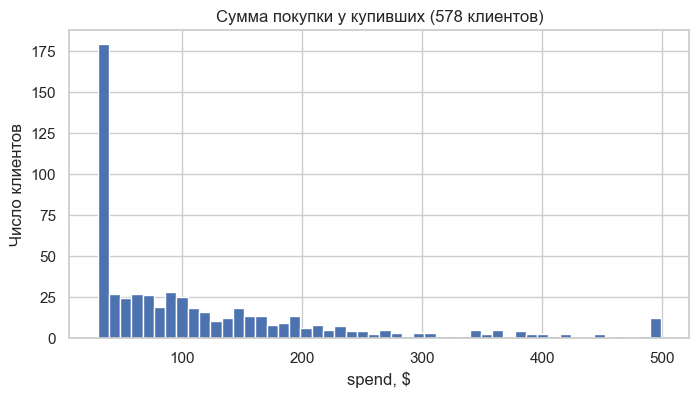

In [27]:
plt.figure(figsize=(8, 4))
plt.hist(buyers['spend'], bins=50)
plt.title('Сумма покупки у купивших (578 клиентов)')
plt.xlabel('spend, $')
plt.ylabel('Число клиентов')
plt.savefig('images/spend_hist.png', dpi=150, bbox_inches='tight')
plt.show()

Распределение сильно скошено вправо: обычно тратят мало, медиана около \$81, но есть хвост до \$499. Две особенности: 136 покупок ровно на \$29.99 (видимо, одна дешёвая позиция) и 12 ровно на \$499, выше которого нет ни одной, похоже на потолок в данных.

### Дубликаты

In [28]:
df.duplicated().sum()

np.int64(6562)

In [29]:
df.duplicated(keep=False).sum()

np.int64(7634)

In [30]:
dups = df[df.duplicated(keep=False)]
dups.value_counts().reset_index(name='repeats').head(10)

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,visit,conversion,spend,segment,repeats
0,10,1) $0 - $100,29.99,0,1,Suburban,1,Phone,0,0,0.0,Mens E-Mail,31
1,10,1) $0 - $100,29.99,1,0,Suburban,0,Web,0,0,0.0,Womens E-Mail,27
2,10,1) $0 - $100,29.99,1,0,Suburban,0,Phone,0,0,0.0,No E-Mail,27
3,10,1) $0 - $100,29.99,0,1,Urban,1,Phone,0,0,0.0,Womens E-Mail,27
4,10,1) $0 - $100,29.99,1,0,Suburban,1,Phone,0,0,0.0,No E-Mail,26
5,10,1) $0 - $100,29.99,1,0,Suburban,1,Web,0,0,0.0,No E-Mail,26
6,10,1) $0 - $100,29.99,0,1,Urban,0,Web,0,0,0.0,Womens E-Mail,25
7,9,1) $0 - $100,29.99,1,0,Suburban,1,Web,0,0,0.0,No E-Mail,25
8,10,1) $0 - $100,29.99,1,0,Urban,0,Web,0,0,0.0,Womens E-Mail,25
9,10,1) $0 - $100,29.99,0,1,Suburban,1,Web,0,0,0.0,Mens E-Mail,25


6562 строки являются повторами более ранних. Всего в повторах участвуют 7634 строки, это 1072 разных профиля.

In [31]:
dups['history_segment'].value_counts()

history_segment
1) $0 - $100      7606
2) $100 - $200      18
3) $200 - $350       6
5) $500 - $750       4
Name: count, dtype: int64

In [32]:
(dups['history'] == 29.99).mean() * 100

np.float64(99.16164527115536)

In [33]:
dups['conversion'].sum()

np.int64(0)

Почти все дубли (99%) это клиенты с `history = 29.99`, то есть купившие за год одну самую дешёвую вещь. Остальные признаки почти все двоичные или с парой значений, а id клиента в данных нет, поэтому такие клиенты неизбежно совпадают целиком. Среди дублей нет ни одной покупки: у купивших `spend` с копейками, совпасть им почти невозможно.

Это разные клиенты с похожими профилями, а не ошибка выгрузки. Удалять их нельзя: так мы выкинем реальных клиентов и сломаем случайное разбиение на группы.

### Решения по данным

1. Исправили опечатку в `zip_code`: `Surburban` -> `Suburban`.
2. Дубликаты оставляем: это разные клиенты с одинаковыми профилями, удаление сломает A/B-тест.
3. Противоречий в данных нет: `conversion` совпадает со `spend > 0`, все купившие заходили на сайт, `history_segment` согласуется с `history`, клиентов без `mens` и `womens` нет.
4. Конверсия очень редкая (0.57% в контроле). Эффекты будут маленькими в абсолютных цифрах, и их легко спутать со случайным шумом. Поэтому сначала считаем MDE: какой эффект тест вообще способен увидеть (шаг 1).
5. Выручка на клиента: 99% нулей и длинный правый хвост у купивших, значит, высокая дисперсия. Распределение совсем не симметричное, поэтому не очевидно, что t-тест тут корректен. Проверим это A/A-симуляциями (шаг 2) и сравним с bootstrap (шаг 4).
6. Колонки после теста (`visit`, `conversion`, `spend`) не используем как признаки или фильтры при сравнении групп, иначе будет утечка. Для проверки рандомизации, CUPED и сегментов берём только признаки до теста.